In [1]:
import pandas as pd
import numpy as np
import lightgbm as lgb
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, roc_curve, auc
from imblearn.over_sampling import SMOTE
from geopy.distance import geodesic
import joblib


In [2]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using:", device)
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))


Using: cuda
NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [3]:
df = pd.read_csv('dataset.csv')
df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [4]:
df.describe

<bound method NDFrame.describe of          Unnamed: 0 trans_date_trans_time               cc_num  \
0                 0   2019-01-01 00:00:18     2703186189652095   
1                 1   2019-01-01 00:00:44         630423337322   
2                 2   2019-01-01 00:00:51       38859492057661   
3                 3   2019-01-01 00:01:16     3534093764340240   
4                 4   2019-01-01 00:03:06      375534208663984   
...             ...                   ...                  ...   
1296670     1296670   2020-06-21 12:12:08       30263540414123   
1296671     1296671   2020-06-21 12:12:19     6011149206456997   
1296672     1296672   2020-06-21 12:12:32     3514865930894695   
1296673     1296673   2020-06-21 12:13:36     2720012583106919   
1296674     1296674   2020-06-21 12:13:37  4292902571056973207   

                                    merchant       category     amt  \
0                 fraud_Rippin, Kub and Mann       misc_net    4.97   
1            fraud_Heller, Gutm

In [5]:
df['tdtt'] = pd.to_datetime(df['trans_date_trans_time'])
df['hour'] = df['tdtt'].dt.hour
df['day'] = df['tdtt'].dt.day
df['month'] = df['tdtt'].dt.month


In [6]:
dropcolumns = ['Unnamed: 0','trans_date_trans_time','first','last','street','city','state','zip','dob','job','trans_num'] 
df= df.drop(columns=dropcolumns)

In [7]:
df.head()

,cc_num,merchant,category,amt,gender,lat,long,city_pop,unix_time,merch_lat,merch_long,is_fraud,tdtt,hour,day,month
0,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,F,36.0788,-81.1781,3495,1325376018,36.011293,-82.048315,0,2019-01-01 00:00:18,0,1,1
1,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,F,48.8878,-118.2105,149,1325376044,49.159047,-118.186462,0,2019-01-01 00:00:44,0,1,1
2,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,M,42.1808,-112.2620,4154,1325376051,43.150704,-112.154481,0,2019-01-01 00:00:51,0,1,1
3,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,M,46.2306,-112.1138,1939,1325376076,47.034331,-112.561071,0,2019-01-01 00:01:16,0,1,1
4,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,M,38.4207,-79.4629,99,1325376186,38.674999,-78.632459,0,2019-01-01 00:03:06,0,1,1


In [8]:
cat_col = ['merchant' , 'category', 'gender']

encoders = {}
for col in cat_col:
    encoders[col]=LabelEncoder()
    df[col ] = encoders[col].fit_transform(df[col])

In [9]:
# def haversine(lat1,lon1,lat2,lon2):
#     return np.array([geodesic((a,b),(c,d)).km for a,b,c,d in zip(lat1,lon1,lat2,lon2)])

# df['distance'] = haversine(df['lat'],df['long'], df['merch_lat'], df['merch_long'])

In [10]:

def haversine(lat1, lon1, lat2, lon2):
    # Move data to GPU
    lat1 = torch.tensor(lat1.to_numpy(), dtype=torch.float32, device="cuda")
    lon1 = torch.tensor(lon1.to_numpy(), dtype=torch.float32, device="cuda")
    lat2 = torch.tensor(lat2.to_numpy(), dtype=torch.float32, device="cuda")
    lon2 = torch.tensor(lon2.to_numpy(), dtype=torch.float32, device="cuda")

    # Degrees -> radians
    lat1 = torch.deg2rad(lat1)
    lon1 = torch.deg2rad(lon1)
    lat2 = torch.deg2rad(lat2)
    lon2 = torch.deg2rad(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        torch.sin(dlat / 2) ** 2
        + torch.cos(lat1)
        * torch.cos(lat2)
        * torch.sin(dlon / 2) ** 2
    )

    c = 2 * torch.asin(torch.sqrt(a))

    # Earth radius in km
    return (6371.0088 * c).cpu().numpy()


df["distance"] = haversine(
    df["lat"],
    df["long"],
    df["merch_lat"],
    df["merch_long"]
)


In [11]:
df.head()

,cc_num,merchant,category,amt,gender,lat,long,city_pop,unix_time,merch_lat,merch_long,is_fraud,tdtt,hour,day,month,distance
0,2703186189652095,514,8,4.97,0,36.0788,-81.1781,3495,1325376018,36.011293,-82.048315,0,2019-01-01 00:00:18,0,1,1,78.597603
1,630423337322,241,4,107.23,0,48.8878,-118.2105,149,1325376044,49.159047,-118.186462,0,2019-01-01 00:00:44,0,1,1,30.212271
2,38859492057661,390,0,220.11,1,42.1808,-112.2620,4154,1325376051,43.150704,-112.154481,0,2019-01-01 00:00:51,0,1,1,108.206238
3,3534093764340240,360,2,45.00,1,46.2306,-112.1138,1939,1325376076,47.034331,-112.561071,0,2019-01-01 00:01:16,0,1,1,95.673958
4,375534208663984,297,9,41.96,1,38.4207,-79.4629,99,1325376186,38.674999,-78.632459,0,2019-01-01 00:03:06,0,1,1,77.556465


In [12]:
features = ['merchant','category','amt','cc_num','hour','day','month','gender','distance']

x= df[features]
y = df['is_fraud']


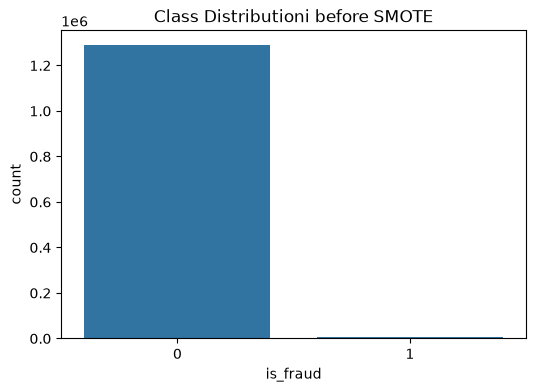

In [13]:
plt.figure(figsize=(6,4))
sns.countplot(x='is_fraud', data=df)
plt.title("Class Distributioni before SMOTE")
plt.show()

In [14]:
smote = SMOTE(random_state=42)
x_resample, y_resample = smote.fit_resample(x,y)

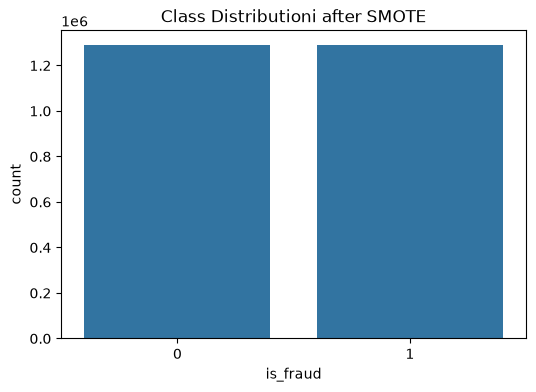

In [15]:
plt.figure(figsize=(6,4))
sns.countplot(x=y_resample)
plt.title("Class Distributioni after SMOTE")
plt.show()

In [16]:
x_train,x_test,y_train,y_test = train_test_split(x_resample,y_resample,test_size=0.2, random_state=42)

In [31]:
lgb_model= lgb.LGBMClassifier(
    boosting_type='gbdt',
    objective='binary',
    metrics ='auc',
    is_unbalance= True,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    n_estimators=200,
    random_state=42
    # device='cuda'
)
lgb_model.fit(x_train,y_train)

[LightGBM] [Info] Number of positive: 1030687, number of negative: 1031983
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007809 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1104
[LightGBM] [Info] Number of data points in the train set: 2062670, number of used features: 9
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499686 -> initscore=-0.001257
[LightGBM] [Info] Start training from score -0.001257


,learning_rate,0.05
,n_estimators,200
,objective,'binary'
,random_state,42
,metrics,'auc'
,is_unbalance,True
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000
,class_weight,None


In [32]:
y_pred = lgb_model.predict(x_test)

In [33]:
print("Classification_Report:\n\n", classification_report(y_test,y_pred))
print("Roc AUc Score:", roc_auc_score(y_test,y_pred))

Classification_Report:

               precision    recall  f1-score   support

           0       0.92      0.97      0.95    257186
           1       0.97      0.92      0.94    258482

    accuracy                           0.94    515668
   macro avg       0.95      0.94      0.94    515668
weighted avg       0.95      0.94      0.94    515668

Roc AUc Score: 0.9447891614769754


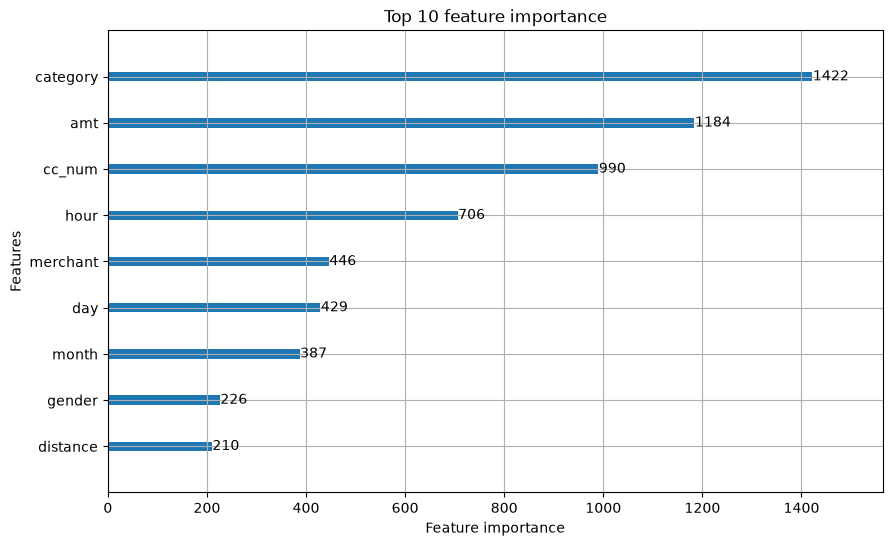

In [34]:
lgb.plot_importance(lgb_model, max_num_features=10, importance_type='split',figsize=(10,6))
plt.title("Top 10 feature importance")
plt.show()

In [35]:
fpr, tpr, threshold = roc_curve(y_test,lgb_model.predict_proba(x_test)[:,1])
roc_auc= auc(fpr,tpr)

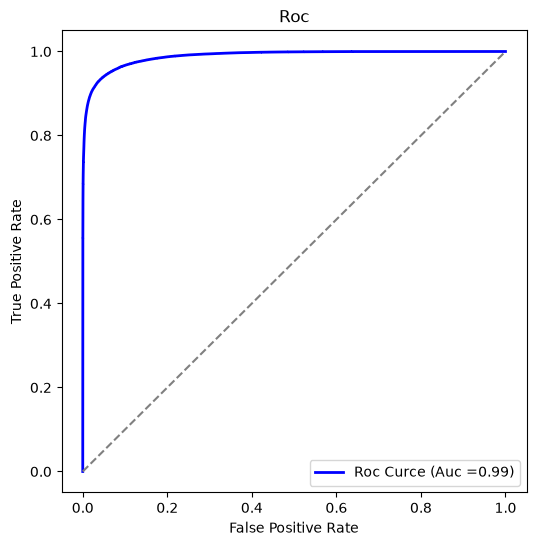

In [38]:
plt.figure(figsize=(6,6))
plt.plot(fpr,tpr,color='blue', lw=2,label= f'Roc Curce (Auc ={roc_auc:.2f})')
plt.plot([0,1],[0,1], color='gray',linestyle='--')
plt.title('Roc')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc="lower right")
plt.show()

In [39]:
joblib.dump(lgb_model,"Fraud_Detection_Model.jb")
joblib.dump(encoders,"label_encoder.jb")

['label_encoder.jb']